In [1]:
pip install numpy pandas seaborn matplotlib scikit-learn scipy tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
df = pd.read_csv("uber.csv")
print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [4]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [5]:
df = df.dropna()

In [6]:
df = df[(df["fare_amount"] > 0 ) & ( df["passenger_count"] > 0)]

In [7]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day

In [13]:
df = df[
    df["pickup_latitude"].between(-90,90) &
    df["dropoff_latitude"].between(-90, 90) &
    df["pickup_longitude"].between(-180 ,180) & 
    df["dropoff_longitude"].between(-180, 180)
    ]


In [15]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers= df[(df["fare_amount"] >= lower) & ( df["fare_amount"] <= upper )]

print( len(outliers))


176046



Correlation:
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000         -0.001506         0.000762   
pickup_longitude     -0.001506          1.000000        -0.980025   
pickup_latitude       0.000762         -0.980025         1.000000   
dropoff_longitude    -0.003080          0.955625        -0.943260   
dropoff_latitude      0.002259         -0.943290         0.963247   
passenger_count       0.014965         -0.001087        -0.000382   
hour                 -0.004091          0.002909        -0.003241   
day                   0.005738          0.003321        -0.006727   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.003080          0.002259         0.014965   
pickup_longitude            0.955625         -0.943290        -0.001087   
pickup_latitude            -0.943260          0.963247        -0.000382   
dropoff_longitude           1.000000         -0.980596        -0

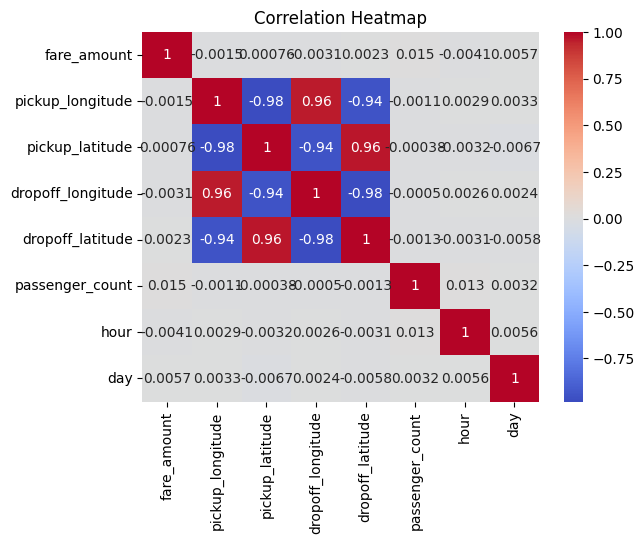

In [16]:

features = [
    "fare_amount", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "hour", "day"
]

correlation = df[features].corr()

print("\nCorrelation:")
print(correlation)

sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [17]:

X = df[[
    "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "hour", "day"
]]

y = df["fare_amount"]


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_r2 = r2_score(y_test, lr_pred)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))


# 9. Random Forest Regression

rf = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

In [20]:

# 10. Compare Models

print("\nMODEL COMPARISON")

print("Linear Regression:")
print("R2 Score:", lr_r2)
print("RMSE:", lr_rmse)

print("\nRandom Forest:")
print("R2 Score:", rf_r2)
print("RMSE:", rf_rmse)





MODEL COMPARISON
Linear Regression:
R2 Score: 0.0001983983412049417
RMSE: 3.6255151339965006

Random Forest:
R2 Score: 0.6969851749364848
RMSE: 1.995927430212467
